## Here Problem Statement i have 3 tools 
1. Internet Search Tool
2. Weather Tool 
3. DB Tool 
user fire an query which call the tools above and get the desire output , if query doesn't belong to any of the tools just return Sorry i don't have for your query kind of message 

In [1]:
## Import os and setup your env
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [2]:
from langchain_openai import ChatOpenAI
llm  = ChatOpenAI(model="gpt-4o", temperature=0)

In [3]:
WEATHER_API_KEY = os.getenv('WEATHER_API_KEY')

In [4]:
##Call weather calling tool
from langchain_core.tools import tool
import requests
@tool
def get_weather(query: str) -> list:
    """Search weatherapi to get the current weather."""
    base_url = "http://api.weatherapi.com/v1/current.json"
    complete_url = f"{base_url}?key={WEATHER_API_KEY}&q={query}"

    response = requests.get(complete_url)
    data = response.json()
    if data.get("location"):
        return data
    else:
        return "Weather Data Not Found"


In [7]:
##Web Search Tool Tavily search
from langchain_community.tools.tavily_search import TavilySearchResults
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, TimeoutError
import requests
import json
from markitdown import MarkItDown

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_10006/3507476813.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [45]:
##Invoke Tavily
from langchain_community.tools.tavily_search import TavilySearchResults
@tool
def search_web_extract_info(query: str) -> list:
    """Search the web for a query and extracts useful information from the search links"""
    doc_result = []
    tavily_tool = TavilySearchResults(max_results=5,
                                  search_depth='advanced',
                                  include_answer=False,
                                  include_raw_content=True)
    results = tavily_tool.invoke(query)
    return results
    



100%|██████████| 5/5 [00:00<00:00, 40642.48it/s]


Create Data base tool

In [26]:
import sqlite3

In [27]:
connection = sqlite3.connect("employees.db")

In [28]:
# Running query on DB which will return all the tables from our sqlite DB
!sqlite3 employees.db "SELECT name FROM sqlite_master WHERE type='table';"

employees


In [29]:
## LangChain provided utility to connect a databse and execute query
from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///employees.db")
db

In [ ]:
from langchain_core.messages import SystemMessage

SQL_PREFIX = """You are an agent designed to interact with a SQL database in SQLite.
Given an input question, create a syntactically correct SQLite query to run, then look at the results of the query and return the answer.
Unless the user specifies a specific number of examples they wish to obtain, always limit your query to at most 3 results.
You can order the results by a relevant column to return the most interesting examples in the database.
Never query for all the columns from a specific table, only ask for the relevant columns given the question.
Make sure you generate a correct SQLite query as plain text without any formatting or code blocks.
Do not include sql or similar markers.
Do not try to explain the query, just provide the query as-is, like this: SELECT ...

You have access to tools for interacting with the database.
Only use the below tools. Only use the information returned by the below tools to construct your final answer.

You MUST double check your query before executing it. If you get an error while executing a query, rewrite the query and try again.
DO NOT make any DML statements (INSERT, UPDATE, DELETE, DROP etc.) to the database even if the user asks.

To start you should ALWAYS look at the tables in the database to see what you can query.
Do NOT skip this step.
Then you should query the schema of the most relevant tables.

When generating the final answer in markdown from the results,
if there are special characters in the text, such as the dollar symbol,
ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5
"""

SYS_PROMPT = SystemMessage(content=SQL_PREFIX)

<>:24: SyntaxWarning: invalid escape sequence '\$'
<>:24: SyntaxWarning: invalid escape sequence '\$'
/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_10006/442152697.py:24: SyntaxWarning: invalid escape sequence '\$'
  ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5


In [31]:
# DB_QUERY, DB_SCHEMA,DB_LIST_TABLES and DB_QUERY_CHECKER are available under LangChain "SQLDatabaseToolkit"

from langchain_community.agent_toolkits import SQLDatabaseToolkit

sql_toolkit = SQLDatabaseToolkit(db=db, llm=llm)

sql_tools = sql_toolkit.get_tools()

# You can see it has 4 tools
sql_tools

[QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x129b78ec0>),
 InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x129b78ec0>),
 ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x129b78ec0>),
 QuerySQLCheckerTool(description='Use this tool to double check if your 

In [33]:
from langchain_core.messages import HumanMessage

In [50]:
tools = [
    get_weather,
    search_web_extract_info,
    *sql_tools
]

In [51]:
tools

[StructuredTool(name='get_weather', description='Search weatherapi to get the current weather.', args_schema=<class 'langchain_core.utils.pydantic.get_weather'>, func=<function get_weather at 0x11a2ed260>),
 StructuredTool(name='search_web_extract_info', description='Search the web for a query and extracts useful information from the search links', args_schema=<class 'langchain_core.utils.pydantic.search_web_extract_info'>, func=<function search_web_extract_info at 0x12b66af20>),
 QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x129b78ec0>),
 InfoSQLDatabaseTool(description='Inp

In [52]:
llm_with_tools = llm.bind_tools(tools)

Define the State 

In [53]:
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [54]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

In [55]:
system_prompt = SystemMessage(content="""
You are an AI assistant with access to three categories of tools:

1. Database / Employee Tools:
   Use database tools for employee-related internal information.

2. Web Search Tool:
   Use search_web_extract_info for general or current public information.

3. Weather Tool:
   Use get_weather for weather-related queries.

Rules:
- Employee information -> Database tools
- General/current public information -> search_web_extract_info
- Weather information -> get_weather
- If multiple tools are required, use the relevant tools.
- Do not call unnecessary tools.
- Use tool results to formulate the final answer.
""")

In [59]:
# ============================================================
# AGENT NODE
# ============================================================

def tool_calling_llm(state: State):

    messages = [system_prompt] + state["messages"]

    response = llm_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

In [58]:
# ============================================================
# TOOL NODE
# ============================================================

tool_node = ToolNode(tools)

In [78]:
# Build the graph
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)

builder.add_node("tools", ToolNode(tools=tools))

builder.add_edge(START, "tool_calling_llm")

# Conditional Edge
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from LLM is a tool call -> tools_condition routes to tools
    # If the latest message (result) from LLM is a not a tool call -> tools_condition routes to END
    tools_condition,
    ["tools", END]
)
builder.add_edge("tools", "tool_calling_llm") # this is the key feedback loop
builder.add_edge("tools", END)
agent = builder.compile()

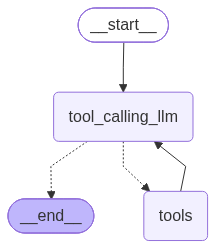

In [79]:
# Display the graph
from IPython.display import display, Image
Image(agent.get_graph().draw_mermaid_png())

In [88]:
def run_agent(query: str):
    for event in agent.stream(
        {"messages": [HumanMessage(content=query)]},
        stream_mode="values"
    ):
        message = event["messages"][-1]

        if hasattr(message, "tool_calls") and message.tool_calls:
            for tool_call in message.tool_calls:
                print(
                    f"\n🔧 Tool Called: {tool_call['name']}"
                    f"\n📥 Arguments: {tool_call['args']}"
                )

        if message.type == "tool":
            print(f"📤 Tool Result: {message.content}")

    print("\n🤖 Final Answer:")
    # message.pretty_print()
    display(Markdown(message.content))

In [89]:
run_agent("What is the latest news on OpenAI product releases")


🔧 Tool Called: search_web_extract_info
📥 Arguments: {'query': 'latest news on OpenAI product releases'}


100%|██████████| 5/5 [00:00<00:00, 37650.84it/s]


📤 Tool Result: [{"title": "OpenAI Research | Release | OpenAI", "content": "Product\n\nJul 9, 2026\n\nGPT-5.6: Frontier intelligence that scales with your ambition More intelligence from every token, stronger performance per dollar, and more capability on demand for your hardest work.\n\nProduct\n\nJul 8, 2026\n\nIntroducing GPT-Live A new generation of voice models for natural human-AI interaction, now powering ChatGPT Voice.\n\nProduct\n\nJun 26, 2026\n\nPreviewing GPT-5.6 Sol: a next-generation model OpenAI previews GPT-5.6 Sol, a next-generation model with stronger capabilities in coding, science, and cybersecurity, paired with its most advanced safety stack.\n\nResearch\n\nJun 4, 2026\n\nDreaming: Better memory for a more helpful ChatGPT ChatGPT introduces a new memory system to better remember preferences, keeping context fresh and relevant across conversations.\n\nProduct [...] Product\n\nJun 3, 2026\n\nIntroducing new capabilities to GPT-Rosalind GPT-Rosalind advances life scie

Here are some of the latest product releases and updates from OpenAI:

1. **GPT-5.6**: Released on July 9, 2026, this model offers enhanced intelligence, stronger performance per dollar, and more capabilities for complex tasks.

2. **GPT-Live**: Introduced on July 8, 2026, this new generation of voice models powers natural human-AI interaction, particularly in ChatGPT Voice.

3. **GPT-5.6 Sol**: Previewed on June 26, 2026, this next-generation model focuses on coding, science, and cybersecurity, with advanced safety features.

4. **GPT-Rosalind**: Released on June 3, 2026, this model enhances life sciences research with improved biological reasoning and experimental workflow capabilities.

5. **GPT-6 Astra**: Launched in September 2026, this is OpenAI's most capable model for professional work, available in ChatGPT Work, Codex, and the API. It offers advanced features for computer use, coding, safety, and enterprise controls.

6. **GPT-Live-1**: Introduced in September 2026, this model supports full-duplex voice conversations in the API, with features like simultaneous listening and speaking, native transcripts, and Codex integration.

7. **ChatGPT for Financial Services**: This tailored experience combines financial data with GPT-6 Astra's reasoning to aid in research, financial modeling, and client materials.

These updates reflect OpenAI's ongoing efforts to enhance AI capabilities across various domains, including voice interaction, cybersecurity, and financial services.

In [90]:
run_agent("Show IT employees with more than 7 years of experience?")


🔧 Tool Called: sql_db_list_tables
📥 Arguments: {}
📤 Tool Result: employees

🔧 Tool Called: sql_db_schema
📥 Arguments: {'table_names': 'employees'}
📤 Tool Result: 
CREATE TABLE employees (
	"Employee" TEXT, 
	"Department" TEXT, 
	"Salary" INTEGER, 
	"Experience" INTEGER, 
	"Location" TEXT
)

/*
3 rows from employees table:
Employee	Department	Salary	Experience	Location
Rajiv	IT	90000	8	Bangalore
Amit	HR	70000	5	Mumbai
Priya	IT	120000	10	Bangalore
*/

🔧 Tool Called: sql_db_query_checker
📥 Arguments: {'query': "SELECT Employee FROM employees WHERE Department = 'IT' AND Experience > 7;"}
📤 Tool Result: ```sql
SELECT Employee FROM employees WHERE Department = 'IT' AND Experience > 7;
```

🔧 Tool Called: sql_db_query
📥 Arguments: {'query': "SELECT Employee FROM employees WHERE Department = 'IT' AND Experience > 7;"}
📤 Tool Result: [('Rajiv',), ('Priya',)]

🤖 Final Answer:


The IT employees with more than 7 years of experience are Rajiv and Priya.

In [91]:
run_agent("What is the weather in Bangalore?")


🔧 Tool Called: get_weather
📥 Arguments: {'query': 'Bangalore'}
📤 Tool Result: {"location": {"name": "Bangalore", "region": "Karnataka", "country": "India", "lat": 12.9833, "lon": 77.5833, "tz_id": "Asia/Kolkata", "localtime_epoch": 1789930156, "localtime": "2026-09-21 00:19"}, "current": {"last_updated_epoch": 1789929000, "last_updated": "2026-09-21 00:00", "temp_c": 21.3, "temp_f": 70.4, "is_day": 0, "condition": {"text": "Moderate or heavy rain shower", "icon": "//cdn.weatherapi.com/weather/64x64/night/356.png", "code": 1243}, "wind_mph": 8.5, "wind_kph": 13.7, "wind_degree": 249, "wind_dir": "WSW", "pressure_mb": 1011.0, "pressure_in": 29.86, "precip_mm": 7.11, "precip_in": 0.28, "humidity": 94, "cloud": 100, "feelslike_c": 22.5, "feelslike_f": 72.5, "windchill_c": 21.3, "windchill_f": 70.4, "heatindex_c": 24.2, "heatindex_f": 75.6, "dewpoint_c": 20.3, "dewpoint_f": 68.5, "vis_km": 7.0, "vis_miles": 4.0, "uv": 0.0, "gust_mph": 14.5, "gust_kph": 23.4, "will_it_rain": 1, "chance_of_r

The current weather in Bangalore is a moderate or heavy rain shower. The temperature is 21.3°C (70.4°F) with a high humidity level of 94%. The wind is blowing from the west-southwest at 13.7 kph (8.5 mph). The visibility is around 7 kilometers (4 miles), and there is a 91% chance of rain.